<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/04_Per_Class_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Per-Class Cross-Dataset Analysis

This notebook compares the Cityscapes clear-condition baseline with the corrected ACDC adverse-condition results.

### Important interpretation

For each semantic class, the broad comparison is calculated as:

**Cross-dataset IoU change = Cityscapes clear IoU − ACDC adverse IoU**

Because Cityscapes and ACDC contain different scenes, locations, object distributions, and image characteristics, this comparison measures a **combined dataset/domain and adverse-condition gap**.

It should not be interpreted as a controlled estimate of the effect of fog, rain, snow, or night alone.

The later matched ACDC analysis provides a more controlled scene-level normal-to-adverse comparison.

### Outputs

1. Combined per-class IoU table
2. Per-class cross-dataset IoU-change table
3. mIoU comparison across conditions
4. Largest measured class-level changes
5. Heatmap of class-by-condition changes
6. Bar charts for selected classes
7. Saved CSV files for later reporting

Mount Drive and define paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CV_Project")

RESULTS_DIR = PROJECT_ROOT / "results"

CITYSCAPES_RESULTS_DIR = RESULTS_DIR / "cityscapes"
ACDC_RESULTS_DIR = RESULTS_DIR / "acdc"

ANALYSIS_RESULTS_DIR = RESULTS_DIR / "analysis"
ANALYSIS_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Results folder:")
print(RESULTS_DIR)

Mounted at /content/drive
Results folder:
/content/drive/MyDrive/CV_Project/results


Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded.")

Libraries loaded.


Load Cityscapes results

In [ ]:
cityscapes_path = (
    CITYSCAPES_RESULTS_DIR
    / "cityscapes_per_class_iou.csv"
)

cityscapes_df = pd.read_csv(
    cityscapes_path
)

print("Cityscapes results:")
display(cityscapes_df)

Cityscapes results:


,class_id,class_name,iou
0,0,road,0.968848
1,1,sidewalk,0.778813
2,2,building,0.877634
3,3,wall,0.533027
4,4,fence,0.456701
5,5,pole,0.389143
6,6,traffic light,0.467573
7,7,traffic sign,0.590998
8,8,vegetation,0.875278
9,9,terrain,0.599791


Load corrected ACDC results

The ACDC values were computed after excluding semantic ignore pixels (`255`) and ACDC invalid/uncertain pixels (`invIds == 1`).

In [ ]:
acdc_path = (
    ACDC_RESULTS_DIR
    / "acdc_per_class_iou.csv"
)

acdc_df = pd.read_csv(
    acdc_path
)

print("ACDC results:")
display(acdc_df)

ACDC results:


,class_id,class_name,fog_iou,rain_iou,snow_iou,night_iou
0,0,road,0.935619,0.827644,0.760996,0.781753
1,1,sidewalk,0.740026,0.320248,0.284740,0.184372
2,2,building,0.816779,0.832880,0.756327,0.798537
3,3,wall,0.542362,0.206293,0.268669,0.281608
4,4,fence,0.508056,0.253767,0.359533,0.323911
5,5,pole,0.542658,0.412011,0.392716,0.447768
6,6,traffic light,0.685615,0.657814,0.643564,0.406088
7,7,traffic sign,0.609482,0.529138,0.511607,0.213859
8,8,vegetation,0.855644,0.886785,0.807798,0.713910
9,9,terrain,0.504168,0.478352,0.087759,0.171628


Verify the two tables match

In [ ]:
print(
    "Cityscapes classes:",
    len(cityscapes_df)
)

print(
    "ACDC classes:",
    len(acdc_df)
)

same_names = (
    cityscapes_df["class_name"].tolist()
    ==
    acdc_df["class_name"].tolist()
)

print(
    "Same class order:",
    same_names
)

Cityscapes classes: 19
ACDC classes: 19
Same class order: True


Create combined IoU table

In [ ]:
combined_df = pd.DataFrame({
    "class_id":
        cityscapes_df["class_id"],

    "class_name":
        cityscapes_df["class_name"],

    "clear_iou":
        cityscapes_df["iou"],

    "fog_iou":
        acdc_df["fog_iou"],

    "rain_iou":
        acdc_df["rain_iou"],

    "snow_iou":
        acdc_df["snow_iou"],

    "night_iou":
        acdc_df["night_iou"],
})

display(combined_df)

,class_id,class_name,clear_iou,fog_iou,rain_iou,snow_iou,night_iou
0,0,road,0.968848,0.935619,0.827644,0.760996,0.781753
1,1,sidewalk,0.778813,0.740026,0.320248,0.284740,0.184372
2,2,building,0.877634,0.816779,0.832880,0.756327,0.798537
3,3,wall,0.533027,0.542362,0.206293,0.268669,0.281608
4,4,fence,0.456701,0.508056,0.253767,0.359533,0.323911
5,5,pole,0.389143,0.542658,0.412011,0.392716,0.447768
6,6,traffic light,0.467573,0.685615,0.657814,0.643564,0.406088
7,7,traffic sign,0.590998,0.609482,0.529138,0.511607,0.213859
8,8,vegetation,0.875278,0.855644,0.886785,0.807798,0.713910
9,9,terrain,0.599791,0.504168,0.478352,0.087759,0.171628


Calculate per-class cross-dataset IoU change

In [ ]:
# Cross-dataset IoU change =
# Cityscapes clear IoU − ACDC adverse IoU

conditions = [
    "fog",
    "rain",
    "snow",
    "night",
]

for condition in conditions:

    combined_df[
        f"{condition}_change"
    ] = (
        combined_df["clear_iou"]
        -
        combined_df[
            f"{condition}_iou"
        ]
    )

display(combined_df)

,class_id,class_name,clear_iou,fog_iou,rain_iou,snow_iou,night_iou,fog_change,rain_change,snow_change,night_change
0,0,road,0.968848,0.935619,0.827644,0.760996,0.781753,0.033229,0.141204,0.207852,0.187096
1,1,sidewalk,0.778813,0.740026,0.320248,0.284740,0.184372,0.038787,0.458565,0.494073,0.594441
2,2,building,0.877634,0.816779,0.832880,0.756327,0.798537,0.060855,0.044754,0.121307,0.079097
3,3,wall,0.533027,0.542362,0.206293,0.268669,0.281608,-0.009335,0.326734,0.264358,0.251420
4,4,fence,0.456701,0.508056,0.253767,0.359533,0.323911,-0.051355,0.202933,0.097168,0.132790
5,5,pole,0.389143,0.542658,0.412011,0.392716,0.447768,-0.153516,-0.022868,-0.003573,-0.058625
6,6,traffic light,0.467573,0.685615,0.657814,0.643564,0.406088,-0.218042,-0.190241,-0.175991,0.061485
7,7,traffic sign,0.590998,0.609482,0.529138,0.511607,0.213859,-0.018484,0.061860,0.079391,0.377139
8,8,vegetation,0.875278,0.855644,0.886785,0.807798,0.713910,0.019634,-0.011507,0.067479,0.161368
9,9,terrain,0.599791,0.504168,0.478352,0.087759,0.171628,0.095623,0.121438,0.512032,0.428163


Create only the cross-dataset change table

Positive values mean the measured IoU is lower on ACDC than on the Cityscapes clear baseline.

Negative values mean the measured IoU is higher on ACDC than on Cityscapes.

Because the two datasets contain different scenes and class distributions, neither direction should be interpreted as a causal weather effect.

In [ ]:
change_df = combined_df[
    [
        "class_id",
        "class_name",
        "fog_change",
        "rain_change",
        "snow_change",
        "night_change",
    ]
].copy()

display(change_df)

,class_id,class_name,fog_change,rain_change,snow_change,night_change
0,0,road,0.033229,0.141204,0.207852,0.187096
1,1,sidewalk,0.038787,0.458565,0.494073,0.594441
2,2,building,0.060855,0.044754,0.121307,0.079097
3,3,wall,-0.009335,0.326734,0.264358,0.251420
4,4,fence,-0.051355,0.202933,0.097168,0.132790
5,5,pole,-0.153516,-0.022868,-0.003573,-0.058625
6,6,traffic light,-0.218042,-0.190241,-0.175991,0.061485
7,7,traffic sign,-0.018484,0.061860,0.079391,0.377139
8,8,vegetation,0.019634,-0.011507,0.067479,0.161368
9,9,terrain,0.095623,0.121438,0.512032,0.428163


Calculate mIoU comparison

In [ ]:
city_summary = pd.read_csv(
    CITYSCAPES_RESULTS_DIR
    / "cityscapes_summary.csv"
)

acdc_summary = pd.read_csv(
    ACDC_RESULTS_DIR
    / "acdc_condition_summary.csv"
)

display(city_summary)
display(acdc_summary)

,dataset,condition,num_images,mIoU
0,Cityscapes,clear,500,0.653285


,condition,num_images,mIoU
0,fog,100,0.696746
1,rain,100,0.500153
2,snow,100,0.487536
3,night,106,0.329382


In [ ]:
miou_comparison = pd.DataFrame({
    "condition": [
        "clear",
        "fog",
        "rain",
        "snow",
        "night",
    ],

    "mIoU": [
        city_summary.loc[0, "mIoU"],
        acdc_summary.loc[
            acdc_summary["condition"] == "fog",
            "mIoU"
        ].iloc[0],
        acdc_summary.loc[
            acdc_summary["condition"] == "rain",
            "mIoU"
        ].iloc[0],
        acdc_summary.loc[
            acdc_summary["condition"] == "snow",
            "mIoU"
        ].iloc[0],
        acdc_summary.loc[
            acdc_summary["condition"] == "night",
            "mIoU"
        ].iloc[0],
    ]
})

display(miou_comparison)

,condition,mIoU
0,clear,0.653285
1,fog,0.696746
2,rain,0.500153
3,snow,0.487536
4,night,0.329382


Overall mIoU cross-dataset change

In [ ]:
clear_miou = (
    miou_comparison.loc[
        miou_comparison["condition"] == "clear",
        "mIoU"
    ].iloc[0]
)

miou_comparison[
    "change_from_clear"
] = (
    clear_miou
    -
    miou_comparison["mIoU"]
)

display(miou_comparison)

,condition,mIoU,change_from_clear
0,clear,0.653285,0.000000
1,fog,0.696746,-0.043462
2,rain,0.500153,0.153132
3,snow,0.487536,0.165749
4,night,0.329382,0.323903


Find largest measured class-level changes for each condition

In [ ]:
for condition in conditions:

    print(
        "\n" + "=" * 60
    )

    print(
        f"LARGEST CROSS-DATASET IoU CHANGES — "
        f"{condition.upper()}"
    )

    print(
        "=" * 60
    )

    top_changes = (
        combined_df[
            [
                "class_name",
                "clear_iou",
                f"{condition}_iou",
                f"{condition}_change",
            ]
        ]
        .sort_values(
            f"{condition}_change",
            ascending=False
        )
        .head(5)
    )

    display(top_changes)


LARGEST CROSS-DATASET IoU CHANGES — FOG


,class_name,clear_iou,fog_iou,fog_change
11,person,0.604533,0.413063,0.191470
18,bicycle,0.605305,0.432888,0.172416
9,terrain,0.599791,0.504168,0.095623
2,building,0.877634,0.816779,0.060855
13,car,0.897410,0.852472,0.044939



LARGEST CROSS-DATASET IoU CHANGES — RAIN


,class_name,clear_iou,rain_iou,rain_change
1,sidewalk,0.778813,0.320248,0.458565
16,train,0.673971,0.258785,0.415186
12,rider,0.363338,0.000000,0.363338
3,wall,0.533027,0.206293,0.326734
15,bus,0.771796,0.476256,0.295540



LARGEST CROSS-DATASET IoU CHANGES — SNOW


,class_name,clear_iou,snow_iou,snow_change
15,bus,0.771796,0.151844,0.619952
9,terrain,0.599791,0.087759,0.512032
1,sidewalk,0.778813,0.284740,0.494073
12,rider,0.363338,0.000000,0.363338
3,wall,0.533027,0.268669,0.264358



LARGEST CROSS-DATASET IoU CHANGES — NIGHT


,class_name,clear_iou,night_iou,night_change
10,sky,0.900408,0.000000,0.900408
15,bus,0.771796,0.000000,0.771796
14,truck,0.700126,0.014218,0.685908
1,sidewalk,0.778813,0.184372,0.594441
9,terrain,0.599791,0.171628,0.428163


Average cross-dataset IoU change across adverse conditions

In [ ]:
combined_df[
    "average_change"
] = (
    combined_df[
        [
            "fog_change",
            "rain_change",
            "snow_change",
            "night_change",
        ]
    ]
    .mean(axis=1)
)

overall_change_ranking = (
    combined_df[
        [
            "class_name",
            "average_change"
        ]
    ]
    .sort_values(
        "average_change",
        ascending=False
    )
)

display(
    overall_change_ranking
)

,class_name,average_change
1,sidewalk,0.396467
15,bus,0.376671
9,terrain,0.289314
14,truck,0.226486
3,wall,0.208294
18,bicycle,0.189619
10,sky,0.180156
12,rider,0.176192
11,person,0.175635
13,car,0.147319


Plot mIoU comparison

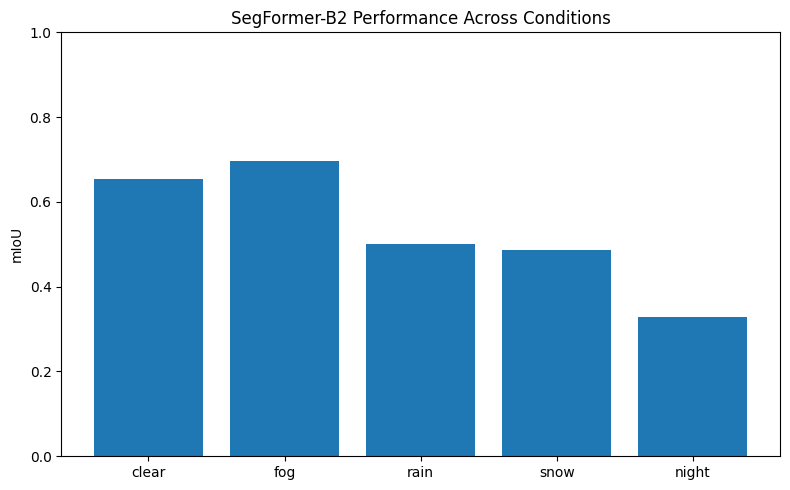

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    miou_comparison["condition"],
    miou_comparison["mIoU"]
)

plt.ylabel("mIoU")

plt.title(
    "SegFormer-B2 Performance Across Conditions"
)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Per-class IoU grouped chart

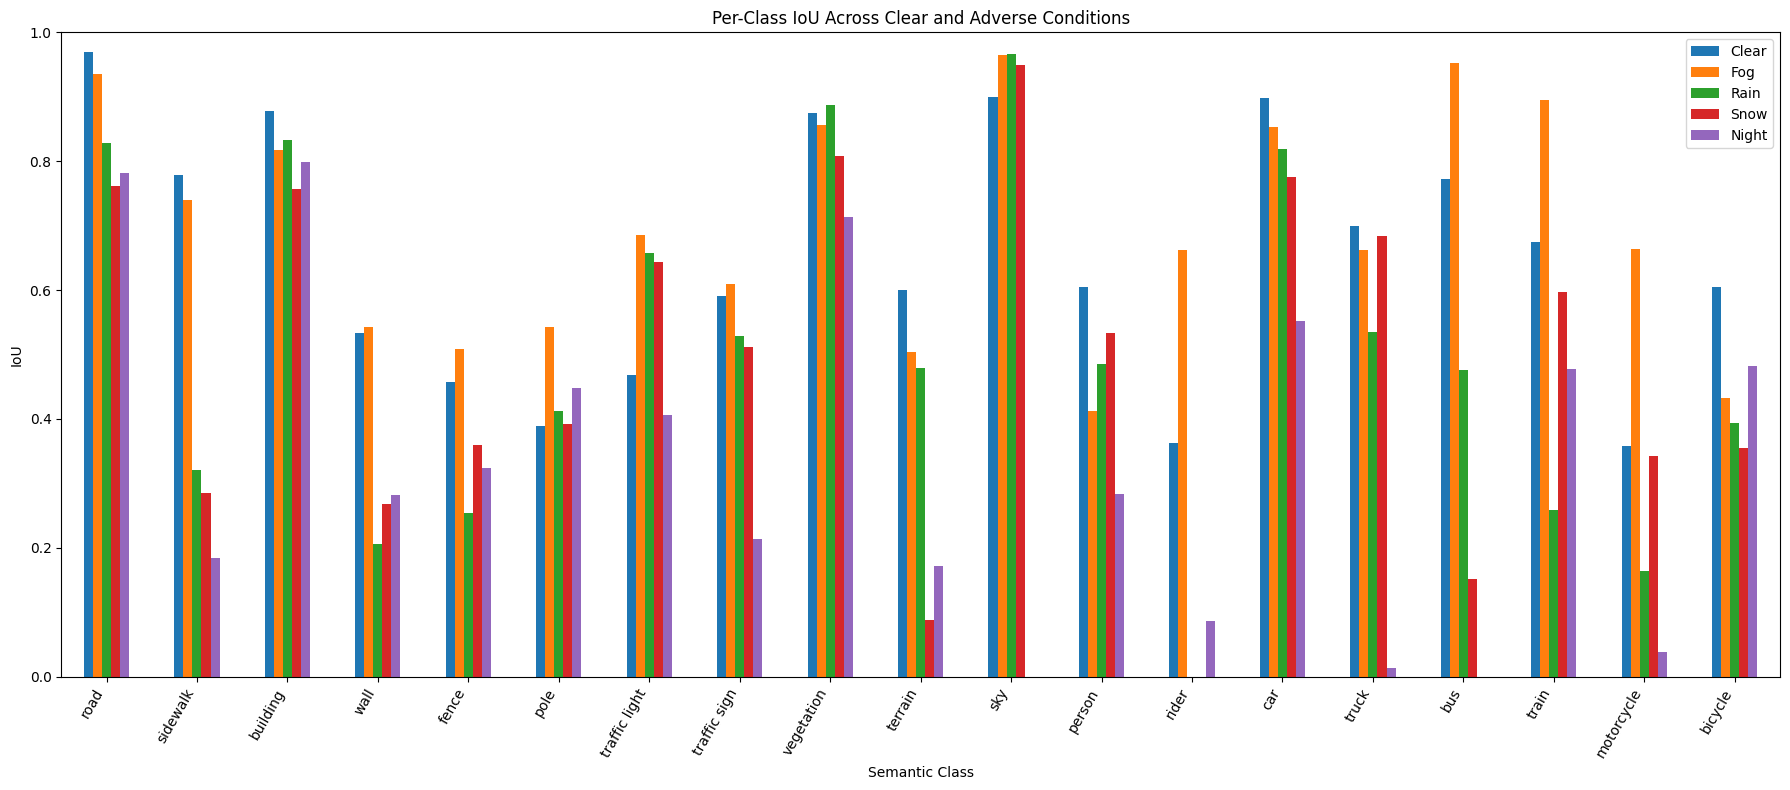

In [ ]:
plot_df = combined_df[
    [
        "class_name",
        "clear_iou",
        "fog_iou",
        "rain_iou",
        "snow_iou",
        "night_iou",
    ]
].set_index(
    "class_name"
)

plot_df.plot(
    kind="bar",
    figsize=(18, 8)
)

plt.ylabel("IoU")

plt.xlabel("Semantic Class")

plt.title(
    "Per-Class IoU Across Clear and Adverse Conditions"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.legend(
    [
        "Clear",
        "Fog",
        "Rain",
        "Snow",
        "Night",
    ]
)

plt.tight_layout()
plt.show()

Cross-dataset IoU-change heatmap

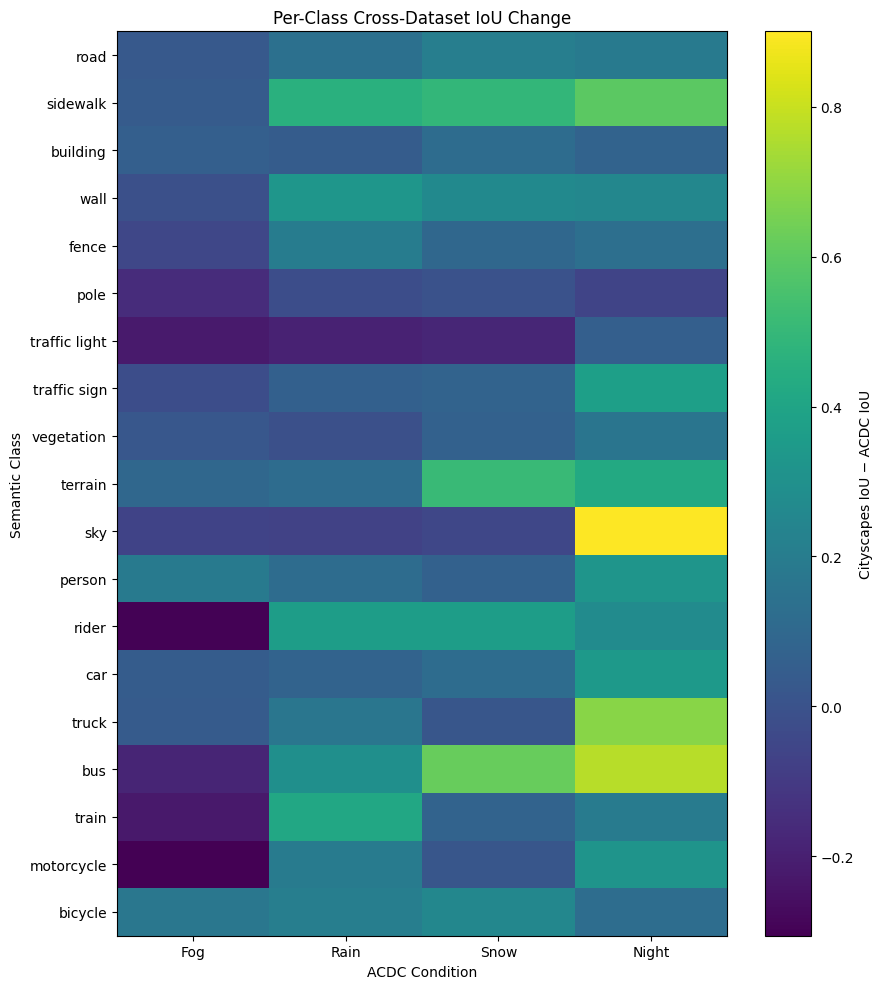

In [ ]:
heatmap_data = change_df[
    [
        "fog_change",
        "rain_change",
        "snow_change",
        "night_change",
    ]
].to_numpy()

fig, ax = plt.subplots(
    figsize=(9, 10)
)

im = ax.imshow(
    heatmap_data,
    aspect="auto"
)

ax.set_xticks(
    range(4)
)

ax.set_xticklabels(
    [
        "Fog",
        "Rain",
        "Snow",
        "Night"
    ]
)

ax.set_yticks(
    range(len(change_df))
)

ax.set_yticklabels(
    change_df["class_name"]
)

ax.set_title(
    "Per-Class Cross-Dataset IoU Change"
)

ax.set_xlabel(
    "ACDC Condition"
)

ax.set_ylabel(
    "Semantic Class"
)

plt.colorbar(
    im,
    ax=ax,
    label="Cityscapes IoU − ACDC IoU"
)

plt.tight_layout()
plt.show()

Add numerical values to heatmap

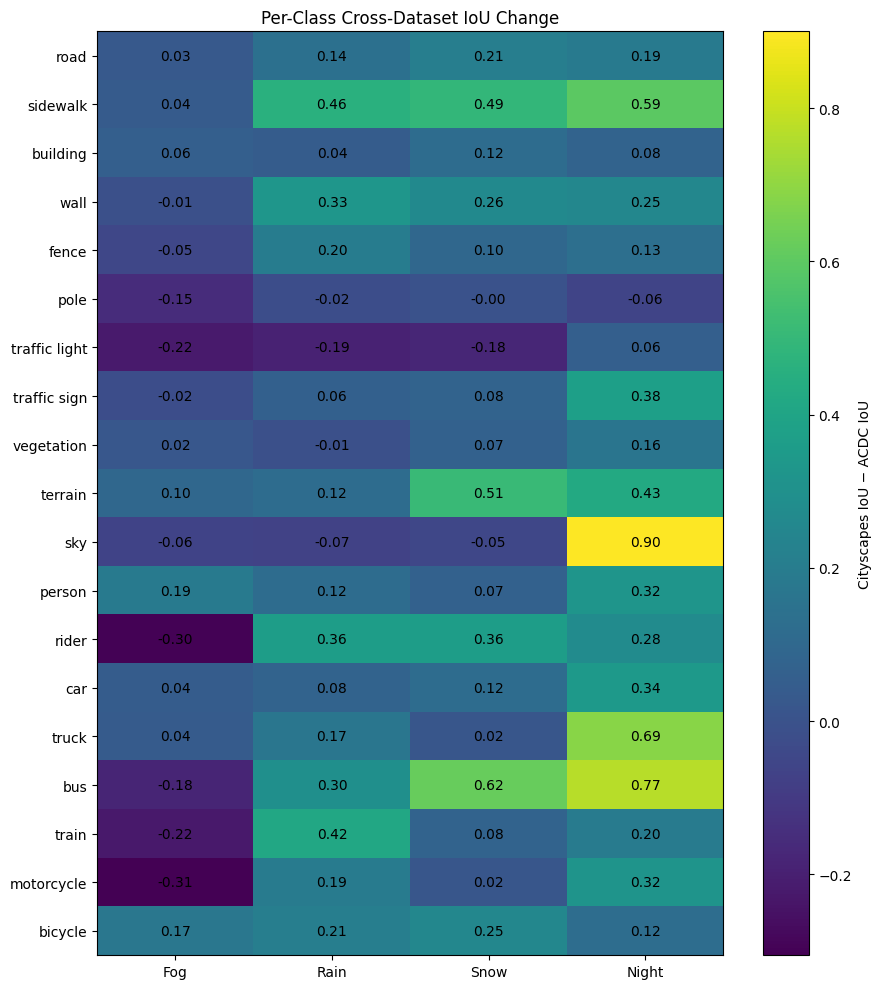

In [ ]:
fig, ax = plt.subplots(
    figsize=(9, 10)
)

im = ax.imshow(
    heatmap_data,
    aspect="auto"
)

ax.set_xticks(
    range(4)
)

ax.set_xticklabels(
    [
        "Fog",
        "Rain",
        "Snow",
        "Night"
    ]
)

ax.set_yticks(
    range(len(change_df))
)

ax.set_yticklabels(
    change_df["class_name"]
)

for i in range(
    heatmap_data.shape[0]
):
    for j in range(
        heatmap_data.shape[1]
    ):

        ax.text(
            j,
            i,
            f"{heatmap_data[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title(
    "Per-Class Cross-Dataset IoU Change"
)

plt.colorbar(
    im,
    ax=ax,
    label="Cityscapes IoU − ACDC IoU"
)

plt.tight_layout()
plt.show()

Plot classes with the largest average cross-dataset IoU change

In [ ]:
top5_classes = (
    overall_change_ranking
    .head(5)["class_name"]
    .tolist()
)

print(
    "Top 5 classes by average "
    "cross-dataset IoU change:"
)

for name in top5_classes:
    print("-", name)

Top 5 classes by average cross-dataset IoU change:
- sidewalk
- bus
- terrain
- truck
- wall


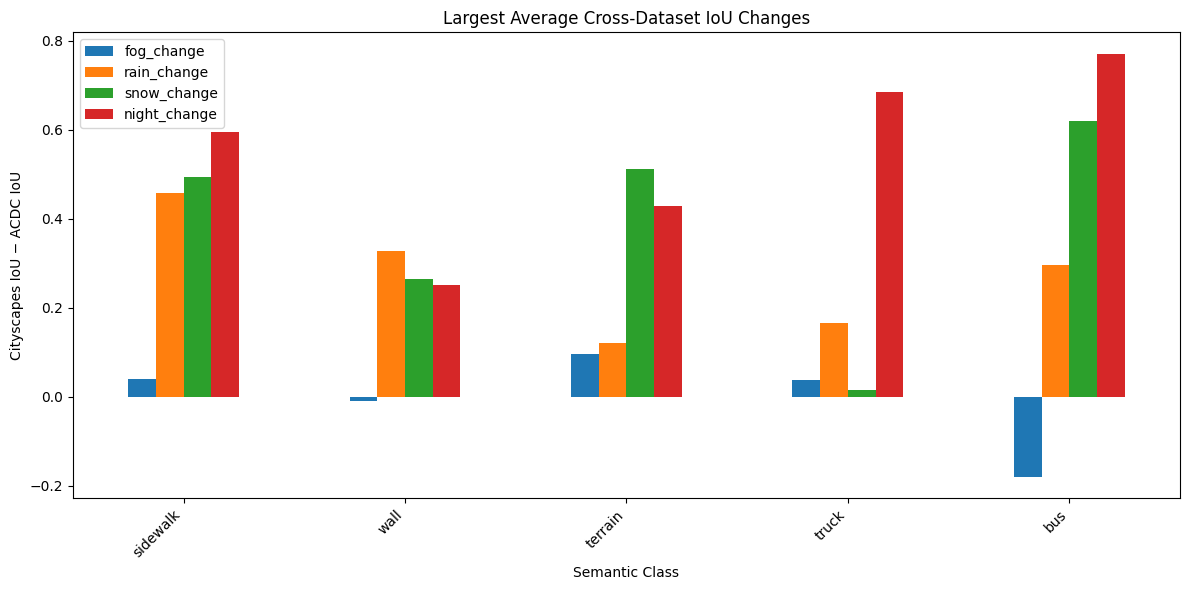

In [ ]:
top5_df = (
    combined_df[
        combined_df[
            "class_name"
        ].isin(top5_classes)
    ]
    .set_index(
        "class_name"
    )
)

top5_df[
    [
        "fog_change",
        "rain_change",
        "snow_change",
        "night_change",
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel(
    "Cityscapes IoU − ACDC IoU"
)

plt.xlabel(
    "Semantic Class"
)

plt.title(
    "Largest Average Cross-Dataset IoU Changes"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

Find strongest class for each condition

In [ ]:
for condition in conditions:

    best = (
        combined_df[
            [
                "class_name",
                f"{condition}_iou"
            ]
        ]
        .sort_values(
            f"{condition}_iou",
            ascending=False
        )
        .head(5)
    )

    print(
        f"\nTop 5 IoU classes under {condition}:"
    )

    display(best)


Top 5 IoU classes under fog:


,class_name,fog_iou
10,sky,0.964370
15,bus,0.952401
0,road,0.935619
16,train,0.895210
8,vegetation,0.855644



Top 5 IoU classes under rain:


,class_name,rain_iou
10,sky,0.966983
8,vegetation,0.886785
2,building,0.832880
0,road,0.827644
13,car,0.819092



Top 5 IoU classes under snow:


,class_name,snow_iou
10,sky,0.949657
8,vegetation,0.807798
13,car,0.776170
0,road,0.760996
2,building,0.756327



Top 5 IoU classes under night:


,class_name,night_iou
2,building,0.798537
0,road,0.781753
8,vegetation,0.713910
13,car,0.552633
18,bicycle,0.482149


Find weakest class for each condition

In [ ]:
for condition in conditions:

    weakest = (
        combined_df[
            [
                "class_name",
                f"{condition}_iou"
            ]
        ]
        .sort_values(
            f"{condition}_iou",
            ascending=True
        )
        .head(5)
    )

    print(
        f"\nLowest 5 IoU classes under {condition}:"
    )

    display(weakest)


Lowest 5 IoU classes under fog:


,class_name,fog_iou
11,person,0.413063
18,bicycle,0.432888
9,terrain,0.504168
4,fence,0.508056
3,wall,0.542362



Lowest 5 IoU classes under rain:


,class_name,rain_iou
12,rider,0.000000
17,motorcycle,0.163335
3,wall,0.206293
4,fence,0.253767
16,train,0.258785



Lowest 5 IoU classes under snow:


,class_name,snow_iou
12,rider,0.000000
9,terrain,0.087759
15,bus,0.151844
3,wall,0.268669
1,sidewalk,0.284740



Lowest 5 IoU classes under night:


,class_name,night_iou
15,bus,0.000000
10,sky,0.000000
14,truck,0.014218
17,motorcycle,0.037633
12,rider,0.086407


Save all cross-dataset analysis tables

In [ ]:
combined_df.to_csv(
    ANALYSIS_RESULTS_DIR
    / "combined_per_class_results.csv",
    index=False
)

change_df.to_csv(
    ANALYSIS_RESULTS_DIR
    / "per_class_cross_dataset_change.csv",
    index=False
)

miou_comparison.to_csv(
    ANALYSIS_RESULTS_DIR
    / "condition_miou_comparison.csv",
    index=False
)

overall_change_ranking.to_csv(
    ANALYSIS_RESULTS_DIR
    / "average_cross_dataset_change.csv",
    index=False
)

print(
    "Analysis tables saved to:"
)

print(
    ANALYSIS_RESULTS_DIR
)

Analysis tables saved to:
/content/drive/MyDrive/CV_Project/results/analysis


Final notebook summary

## Analysis Summary

This notebook compared the fixed SegFormer-B2 model across the Cityscapes clear baseline and the corrected ACDC adverse-condition validation subsets.

The ACDC values used here exclude both semantic ignore pixels and ACDC invalid/uncertain pixels.

The analysis quantified:

- overall mIoU differences between Cityscapes and each ACDC condition,
- per-class IoU under each condition,
- per-class **cross-dataset IoU change**,
- the classes showing the largest measured differences.

These values should not be interpreted as controlled weather degradation because the Cityscapes and ACDC images are not matched scenes.

The differences combine dataset/domain effects with adverse-condition effects.

A later matched ACDC analysis will use normal/adverse scene correspondences to provide stronger control over the dataset difference, while still acknowledging that dynamic objects may differ between paired captures.